# Pump It Up: Predicting Waterpoint Operating Condition

AI7101 — Machine Learning with Python  
Majid Alredha · Hamad Alhosani · Hamdan Alhammadi

This project predicts whether a Tanzanian waterpoint is functional, functional but needs repair, or non-functional. The practical aim is to help water authorities prioritize inspections when resources are limited.

We compare eight classifiers using macro-F1, which gives each class equal importance, and use inverse-frequency training weights wherever supported. The analysis connects classification results to an illustrative inspection policy. Predictions indicate recorded operating condition; they do not establish drinking-water safety, predict future failures, or demonstrate the benefits of maintenance.


## 1. Setup and workflow

The workflow reserves a holdout set, explores the development data, prepares features, compares classifiers using cross-validation, evaluates the selected model, and produces a competition submission.

The saved run uses all 47,520 development records and five stratified folds (`QUICK_RUN=False`). Quick mode uses a stratified sample of 9,000 records and three folds; it skips holdout evaluation and submission generation. Each comparison uses the same records and folds across models. A fixed random seed supports reproducibility, although package versions and execution environments can affect results.

Results discussed below are taken from the saved full run. These are static markdown cells and must be updated if a later run changes the results.


In [1]:
from pathlib import Path
from time import perf_counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import xgboost

from IPython.display import display
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.utils.validation import check_is_fitted
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
    make_scorer,
    classification_report,
    confusion_matrix,
)

from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    BaggingClassifier,
)

from xgboost import XGBClassifier

SEED = 42

# The quick comparison uses a stratified 9,000-row sample.
QUICK_RUN = False
N_SPLITS = 3 if QUICK_RUN else 5

# Tune hyperparameters and select the winning model by macro-F1.
PRIMARY_METRIC = "macro_f1"

RUN_FINAL_EVALUATION = True

REPO_ROOT = Path.cwd()
if not (REPO_ROOT / "data" / "raw").is_dir():
    REPO_ROOT = REPO_ROOT.parent
DATA_DIR = REPO_ROOT / "data" / "raw"
if not DATA_DIR.is_dir():
    raise FileNotFoundError("Run from the repository root or notebooks/.")
OUTPUT_DIR = REPO_ROOT / "outputs"
OUTPUT_DIR.mkdir(exist_ok=True)

CLASS_NAMES = ["functional", "functional needs repair", "non functional"]

# Numeric labels are required by XGBoost.
# All models will use the same encoding.
label_to_number = {name: number for number, name in enumerate(CLASS_NAMES)}
number_to_label = {number: name for name, number in label_to_number.items()}

sns.set_theme(style="whitegrid")
sklearn.set_config(working_memory=128)

print("scikit-learn:", sklearn.__version__)
print("XGBoost:", xgboost.__version__)
print("Quick run:", QUICK_RUN)
print("CV folds:", N_SPLITS)


scikit-learn: 1.9.1
XGBoost: 3.4.1
Quick run: False
CV folds: 5


## 2. Load and align the data

The competition provides 59,400 labeled waterpoints, 39 predictor fields, and 14,850 unlabeled test records. Predictors describe location, infrastructure, water availability, funding, and management. Training labels are joined to predictors by the unique waterpoint `id`; the loading code checks IDs, label completeness, and matching train/test columns.

The identifier is excluded from model inputs. The target retains all three operating conditions, encoded consistently across models:

| Label | Operating condition | Training records | Share |
|---|---|---:|---:|
| `0` | Functional | 32,259 | 54.31% |
| `1` | Functional needs repair | 4,317 | 7.27% |
| `2` | Non-functional | 22,824 | 38.42% |

The competition test records have no supplied labels and are used only to produce final predictions. [DrivenData dataset documentation](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/) describes the fields and target.


In [2]:
# Merge using ID so every pump receives the correct label.

train_values = pd.read_csv(DATA_DIR / "train_values.csv")
train_labels = pd.read_csv(DATA_DIR / "train_labels.csv")
test_values = pd.read_csv(DATA_DIR / "test_values.csv")
submission_format = pd.read_csv(DATA_DIR / "submission_format.csv")

# Check the IDs before joining or making predictions.
for frame in [train_values, train_labels, test_values, submission_format]:
    assert frame["id"].is_unique

assert set(train_values["id"]) == set(train_labels["id"])
assert set(test_values["id"]) == set(submission_format["id"])
assert set(train_values["id"]).isdisjoint(test_values["id"])
assert set(train_values.columns) == set(test_values.columns)

df = train_values.merge(train_labels, on="id", how="left", validate="one_to_one")

assert df["status_group"].notna().all()
assert set(df["status_group"]) == set(CLASS_NAMES)

# Remove the target and identifier from the model inputs.
X = df.drop(columns=["id", "status_group"])

# Encoding changes the label representation, not the classification task.
# 0 = functional, 1 = needs repair, 2 = non functional.
y = df["status_group"].map(label_to_number).astype(int)

X_test = test_values.drop(columns="id")

print("Training inputs:", X.shape)
print("Training target:", y.shape)
print("Competition test inputs:", X_test.shape)

display(df.head())


Training inputs: (59400, 39)
Training target: (59400,)
Competition test inputs: (14850, 39)


,id,amount_tsh,date_recorded,funder,gps_height,installer,longitude,latitude,wpt_name,num_private,...,water_quality,quality_group,quantity,quantity_group,source,source_type,source_class,waterpoint_type,waterpoint_type_group,status_group
0,69572,6000.0,2011-03-14,Roman,1390,Roman,34.938093,-9.856322,none,0,...,soft,good,enough,enough,spring,spring,groundwater,communal standpipe,communal standpipe,functional
1,8776,0.0,2013-03-06,Grumeti,1399,GRUMETI,34.698766,-2.147466,Zahanati,0,...,soft,good,insufficient,insufficient,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional
2,34310,25.0,2013-02-25,Lottery Club,686,World vision,37.460664,-3.821329,Kwa Mahundi,0,...,soft,good,enough,enough,dam,dam,surface,communal standpipe multiple,communal standpipe,functional
3,67743,0.0,2013-01-28,Unicef,263,UNICEF,38.486161,-11.155298,Zahanati Ya Nanyumbu,0,...,soft,good,dry,dry,machine dbh,borehole,groundwater,communal standpipe multiple,communal standpipe,non functional
4,19728,0.0,2011-07-13,Action In A,0,Artisan,31.130847,-1.825359,Shuleni,0,...,soft,good,seasonal,seasonal,rainwater harvesting,rainwater harvesting,surface,communal standpipe,communal standpipe,functional


## 3. Reserve a holdout set

A stratified 80/20 split leaves 47,520 records for development and reserves 11,880 for evaluation. Stratification keeps the three class proportions approximately equal across the two sets.

Exploration, preprocessing choices, and hyperparameter searches use development data. The holdout is excluded from fitting and configuration searches. However, its results have been reviewed during project development, so the current holdout should not be described as a completely independent final audit. Further tuning decisions should use development-set validation; a fresh evaluation or field pilot is needed for a stronger estimate of deployment performance.

A random split measures performance among similarly sampled records. It does not establish generalization to an unseen region or collection period.


In [3]:
# Stratification preserves class proportions in both sets.
# Use development data for all feature and model decisions.

X_dev, X_holdout, y_dev, y_holdout = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)

eda = X_dev.copy()
eda["status_group"] = y_dev.map(number_to_label)

print("Development rows:", len(X_dev))
print("Holdout rows:", len(X_holdout))

class_summary = eda["status_group"].value_counts().to_frame("count")
class_summary["percent"] = 100 * class_summary["count"] / len(eda)

display(class_summary)


Development rows: 47520
Holdout rows: 11880


,count,percent
status_group,,
functional,25807,54.307660
non functional,18259,38.423822
functional needs repair,3454,7.268519


## 4. Explore the development data

The development set contains 25,807 functional waterpoints (54.31%), 3,454 repair cases (7.27%), and 18,259 non-functional waterpoints (38.42%). This imbalance makes accuracy alone insufficient: a classifier predicting only the majority class can exceed 54% accuracy while identifying no repair cases.

The missingness and cardinality table highlights data-quality and representation choices. `scheme_name` is missing in 48.51% of development records, while waterpoint and subvillage names contain many distinct values. Rare categories require careful encoding to avoid relying on poorly supported groups.

Missing-value counts also miss placeholder measurements. Approximately 34.8% of construction years and 3.0% of longitudes are zero, motivating explicit validity checks before imputation.


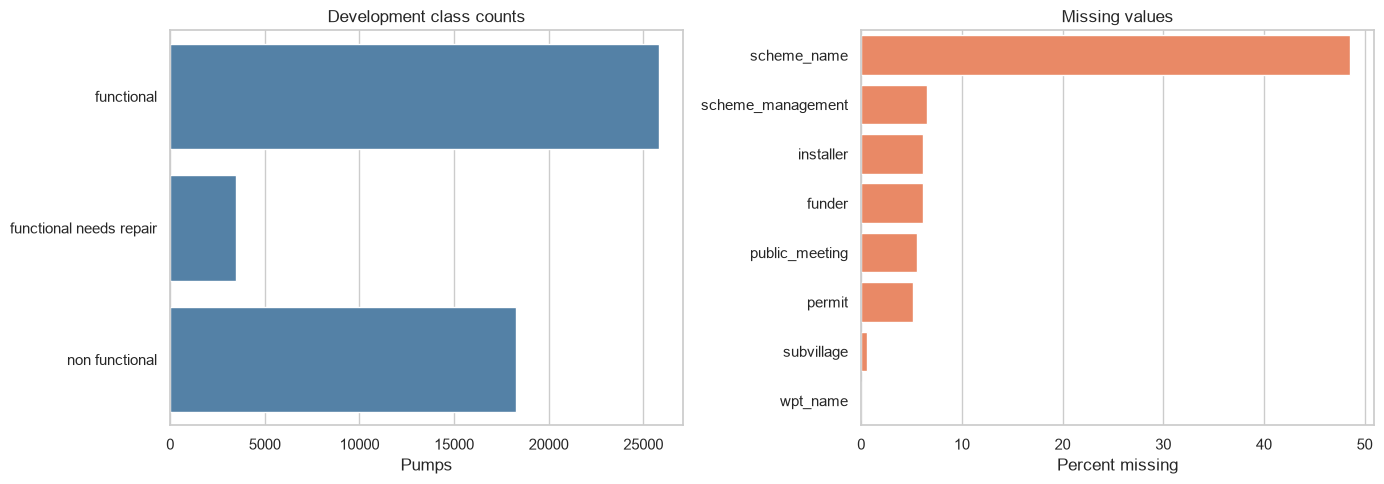

In [4]:
# Imbalance motivates stratified CV and reporting macro-F1.

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.countplot(
    data=eda, y="status_group", order=CLASS_NAMES, color="steelblue", ax=axes[0]
)
axes[0].set(title="Development class counts", xlabel="Pumps", ylabel="")

missing = X_dev.isna().mean().mul(100).sort_values(ascending=False)
missing = missing[missing > 0]

sns.barplot(x=missing.values, y=missing.index, color="coral", seed=SEED, ax=axes[1])
axes[1].set(title="Missing values", xlabel="Percent missing", ylabel="")

plt.tight_layout()
plt.show()


In [5]:
display(
    pd.DataFrame(
        {"unique_values": X_dev.nunique(), "missing_percent": X_dev.isna().mean() * 100}
    )
)


,unique_values,missing_percent
amount_tsh,94,0.000000
date_recorded,349,0.000000
funder,1715,6.115320
gps_height,2401,0.000000
installer,1929,6.138468
longitude,46029,0.000000
latitude,46027,0.000000
wpt_name,30660,0.004209
num_private,59,0.000000
basin,9,0.000000


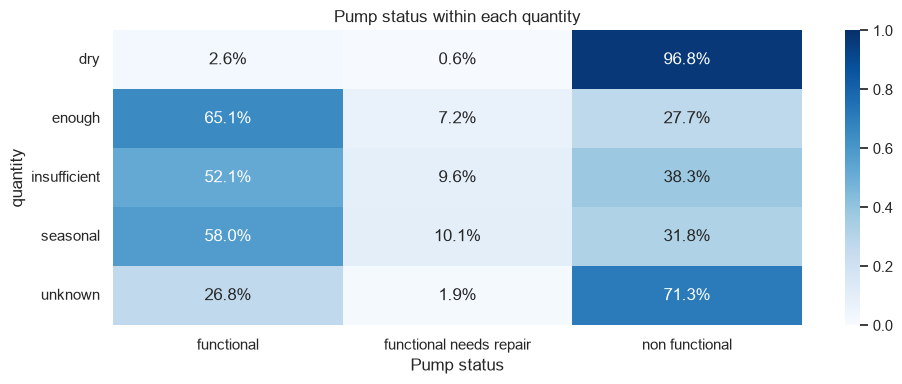

In [6]:
# Row percentages make differently sized categories easier to compare.
# Always check category counts before interpreting extreme percentages.


def plot_status_by_category(feature):
    proportions = pd.crosstab(
        eda[feature], eda["status_group"], normalize="index"
    ).reindex(columns=CLASS_NAMES, fill_value=0)

    plt.figure(figsize=(10, 4))

    sns.heatmap(proportions, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1)

    plt.title(f"Pump status within each {feature}")
    plt.xlabel("Pump status")
    plt.tight_layout()
    plt.show()


plot_status_by_category("quantity")


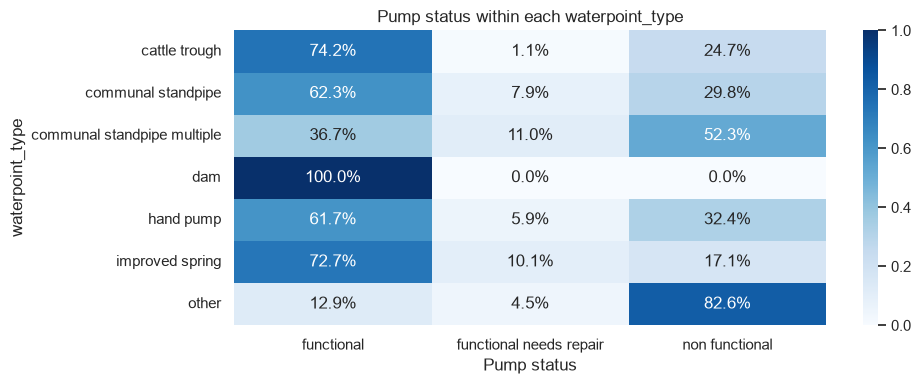

In [7]:
plot_status_by_category("waterpoint_type")


In [8]:
for feature in ["quantity", "waterpoint_type"]:
    display(eda[feature].value_counts().to_frame("pumps"))


,pumps
quantity,
enough,26567
insufficient,12153
dry,4921
seasonal,3244
unknown,635


,pumps
waterpoint_type,
communal standpipe,22778
hand pump,14015
other,5138
communal standpipe multiple,4864
improved spring,631
cattle trough,89
dam,5


### Interpretation of the exploratory analysis

Water availability is strongly associated with operating condition: approximately 96.8% of dry waterpoints in the development set are non-functional. Waterpoint type also separates groups; approximately 82.6% of records in the `other` category are non-functional. These patterns support retaining both predictors and comparing models capable of nonlinear relationships. They do not establish causation.

Category size matters. Only five development records have waterpoint type `dam`, so their class proportions provide little evidence about future cases. Geographic concentration also motivates retaining location information while testing generalization beyond random splits.


## 5. Prepare features

Feature engineering applies deterministic rules to each row, without using target labels or statistics from other records. The same rules are applied to development, holdout, and competition inputs. The resulting development data have 31 fields.

Imputation, category grouping, encoding, and optional scaling are fitted inside each model pipeline. During cross-validation, these fitted transformations use only the training portion of the fold.


### Feature-engineering decisions

| Transformation | Reason and trade-off |
|---|---|
| Drop `recorded_by` and `quantity_group` | Development-data checks confirm that the first is constant and the second duplicates `quantity`. |
| Drop `wpt_name`, `subvillage`, `scheme_name`, and `ward` | Reduce sparsely supported categories and extensive scheme-name missingness. Coordinates, region, LGA, and district retain location context, but useful local detail may be lost. |
| Retain detailed extraction, management, payment, quality, source, and waterpoint fields; drop selected grouped variants | Reduce overlapping descriptions. Grouped fields coarsen related information and are not all exact duplicates. |
| Validate construction year; derive pump age and recording year | Treat nonpositive construction years and construction after observation as missing. Age may capture wear; recording year may capture collection-period differences. |
| Encode recording month with sine and cosine | Represent seasonality while keeping December and January close. |
| Flag and replace invalid coordinate pairs | Longitude zero, near-zero latitude, or either missing coordinate triggers a missing-location indicator and replaces both coordinates with missing values. This rule does not check every possible geographic error. |
| Add zero indicators for population, elevation, and `amount_tsh` | Preserve potentially informative zeros without assuming every zero means missing. |
| Replace population and `amount_tsh` with `log1p` versions | Compress skewed nonnegative values; negative values are clipped to zero before transformation. `amount_tsh` is documented as total static head, rather than a monetary amount. |
| Combine region/district codes and normalize categorical text | Treat administrative codes as categories; standardize case and surrounding whitespace while preserving missing values. |

### Retained predictors

In addition to the engineered age, date, district, log, zero-indicator, and missing-location features above, the models retain these original fields:

| Information | Retained fields |
|---|---|
| Location and elevation | `longitude`, `latitude`, `gps_height`, `basin`, `region`, `lga` |
| Funding and installation | `funder`, `installer` |
| Administration and community | `num_private` (the supplied private-waterpoint count field), `public_meeting`, `scheme_management`, `management`, `permit`, `payment` |
| Infrastructure and water | `construction_year` (after validity checks), `extraction_type`, `water_quality`, `quantity`, `source`, `waterpoint_type` |

These fields provide complementary context; retaining a predictor does not establish its importance or causal relationship with operating condition. Raw recording date, region/district codes, population, and `amount_tsh` are replaced by the corresponding engineered representations.


In [9]:
# These rules use individual rows, not statistics learned from other rows.
# Imputation and encoding will be learned inside each CV fold.

DROP_COLUMNS = [
    "recorded_by",  # Constant in these data.
    "wpt_name",  # Many nearly unique names.
    "subvillage",  # High cardinality; excluded in the initial model.
    "scheme_name",  # High cardinality and substantial missingness.
    "ward",  # High cardinality; coordinates and district retain location context.
    "quantity_group",  # Duplicate of quantity.
    "extraction_type_group",
    "extraction_type_class",
    "management_group",
    "payment_type",
    "quality_group",
    "source_type",
    "source_class",
    "waterpoint_type_group",
]

# Check that these columns are redundant in the development data.
assert X_dev["recorded_by"].nunique(dropna=False) == 1
assert X_dev["quantity"].equals(X_dev["quantity_group"])


def engineer_features(frame):
    data = frame.copy()

    # Year 0 is invalid; construction after observation is inconsistent.
    recorded = pd.to_datetime(data["date_recorded"], errors="coerce")
    year = pd.to_numeric(data["construction_year"], errors="coerce")
    year = year.mask((year <= 0) | (year > recorded.dt.year))

    data["construction_year"] = year
    data["pump_age"] = recorded.dt.year - year
    data["record_year"] = recorded.dt.year

    # Cyclic month features place December near January.
    month = recorded.dt.month
    data["month_sin"] = np.sin(2 * np.pi * (month - 1) / 12)
    data["month_cos"] = np.cos(2 * np.pi * (month - 1) / 12)

    # Flag implausible or missing coordinate pairs.
    bad_coordinates = (
        data["longitude"].eq(0)
        | np.isclose(data["latitude"], 0, atol=1e-6)
        | data[["longitude", "latitude"]].isna().any(axis=1)
    )

    data["coordinates_missing"] = bad_coordinates.astype(int)
    data.loc[bad_coordinates, ["longitude", "latitude"]] = np.nan

    # Preserve ambiguous zeros and give models explicit zero indicators.
    for column in ["population", "gps_height", "amount_tsh"]:
        data[column + "_is_zero"] = data[column].eq(0).astype(int)

    # Compress skewed nonnegative measurements for KNN and logistic regression.
    for column in ["population", "amount_tsh"]:
        data[column + "_log1p"] = np.log1p(data[column].clip(lower=0))

    # Administrative codes are category labels, not numeric distances.
    data["district_id"] = (
        data["region_code"].astype(str) + "_" + data["district_code"].astype(str)
    )

    data = data.drop(
        columns=DROP_COLUMNS
        + ["date_recorded", "region_code", "district_code", "population", "amount_tsh"]
    )

    # Standardize text while preserving genuinely missing values.
    categorical = data.select_dtypes(include=["object", "string", "bool"]).columns

    for column in categorical:
        data[column] = data[column].map(
            lambda value: str(value).strip().lower() if pd.notna(value) else np.nan
        )
        data[column] = data[column].replace("", np.nan)

    return data


X_dev_clean = engineer_features(X_dev)
X_holdout_clean = engineer_features(X_holdout)
X_test_clean = engineer_features(X_test)

display(X_dev_clean.head())
print("Prepared development shape:", X_dev_clean.shape)


,funder,gps_height,installer,longitude,latitude,num_private,basin,region,lga,public_meeting,...,record_year,month_sin,month_cos,coordinates_missing,population_is_zero,gps_height_is_zero,amount_tsh_is_zero,population_log1p,amount_tsh_log1p,district_id
43360,NaN,0,NaN,33.542898,-9.174777,0,lake nyasa,mbeya,rungwe,true,...,2011,1.224647e-16,-1.0,0,1,1,1,0.000000,0.000000,12_4
7263,rc church,2049,acra,34.665760,-9.308548,0,rufiji,iringa,njombe,true,...,2011,8.660254e-01,0.5,0,0,0,0,5.170484,6.216606,11_4
2486,donor,290,do,38.238568,-6.179919,0,wami / ruvu,pwani,bagamoyo,true,...,2011,8.660254e-01,0.5,0,0,0,0,7.741099,3.258097,6_1
313,government of tanzania,0,dwe,30.716727,-1.289055,0,lake victoria,kagera,karagwe,true,...,2011,1.224647e-16,-1.0,0,1,1,1,0.000000,0.000000,18_1
52726,water,0,gove,35.389331,-6.399942,0,internal,dodoma,bahi,true,...,2011,8.660254e-01,0.5,0,1,1,1,0.000000,0.000000,1_6


Prepared development shape: (47520, 31)


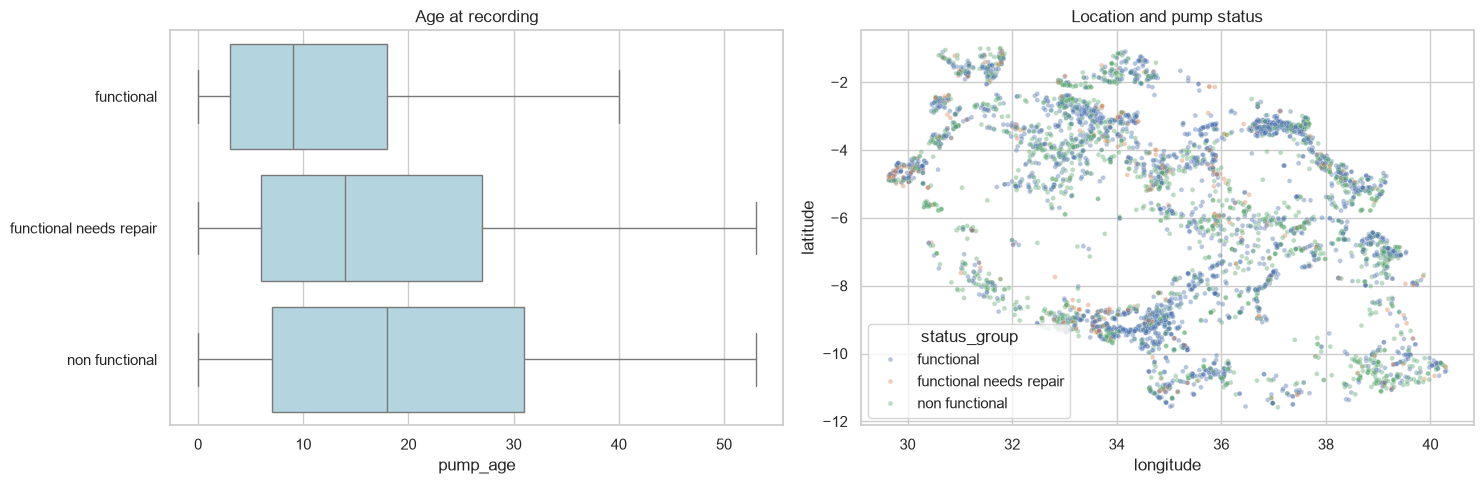

In [10]:
# Spatial clustering can limit generalization to unseen regions.

plot_data = X_dev_clean.copy()
plot_data["status_group"] = y_dev.map(number_to_label)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(
    data=plot_data,
    x="pump_age",
    y="status_group",
    order=CLASS_NAMES,
    showfliers=False,
    color="lightblue",
    ax=axes[0],
)
axes[0].set(title="Age at recording", ylabel="")

sample = plot_data.sample(n=min(5000, len(plot_data)), random_state=SEED)

sns.scatterplot(
    data=sample,
    x="longitude",
    y="latitude",
    hue="status_group",
    hue_order=CLASS_NAMES,
    alpha=0.4,
    s=12,
    ax=axes[1],
)
axes[1].set_title("Location and pump status")

plt.tight_layout()
plt.show()


## 6. Compare models with cross-validation

**Macro-F1 is the selection metric.** It averages the F1 scores of the three classes equally, balancing precision and recall without allowing the largest class to dominate. Accuracy and repair-class recall remain reporting metrics. Repair recall measures the share of actual `functional needs repair` cases identified correctly.

Every model uses the same shuffled stratified folds. Grid search selects each model's hyperparameters by mean validation macro-F1 and refits its best configuration on the full development data. Model families are then ranked by macro-F1, with accuracy as the tie-breaker. Validation scores are not class-weighted.

The saved run contains 29 configurations and 145 cross-validation fits, followed by refitting each family's best configuration. Fold standard deviations describe score variation; they are not confidence intervals. Selecting configurations on these same folds can make the winning CV score optimistic.


### Preprocessing within each training fold

Numeric features use median imputation with missingness indicators. Categorical missing values receive an explicit `__missing__` category. One-hot encoding represents nominal categories without imposing a numeric order.

Categories occurring fewer than 20 times in a training fold are grouped, with at most 50 output categories per field. This limits feature count but discards detail in rare locations and organizations. Unseen categories map to the infrequent group when one exists; otherwise they produce all-zero indicators for that field.

KNN and logistic regression also standardize numeric inputs because distances and regularized coefficients depend on scale. Tree models use unscaled numeric inputs. Every fitted preprocessing step is learned from the training fold and reused for its validation records.

One-hot features use a sparse representation to reduce memory use. Numeric missingness indicators are added for fields with missing values when the imputer is fitted; this differs from the explicit zero and coordinate indicators created during feature engineering.


In [11]:
# All learned preprocessing is fitted inside the training fold.
# Numeric scaling is used only for KNN and multinomial logistic regression.

numeric_columns = X_dev_clean.select_dtypes(include="number").columns.tolist()
categorical_columns = X_dev_clean.columns.difference(numeric_columns).tolist()


def make_pipeline(model, scale_numeric=False):
    numeric_steps = [("impute", SimpleImputer(strategy="median", add_indicator=True))]

    if scale_numeric:
        numeric_steps.append(("scale", StandardScaler()))

    categorical_steps = Pipeline(
        [
            ("impute", SimpleImputer(strategy="constant", fill_value="__missing__")),
            (
                "encode",
                OneHotEncoder(
                    handle_unknown="infrequent_if_exist",
                    min_frequency=20,
                    max_categories=50,
                    sparse_output=True,
                ),
            ),
        ]
    )

    preprocess = ColumnTransformer(
        [
            ("numeric", Pipeline(numeric_steps), numeric_columns),
            ("categorical", categorical_steps, categorical_columns),
        ],
        sparse_threshold=1.0,
    )

    return Pipeline([("preprocess", preprocess), ("model", model)])


class ClassWeightedXGBoost(ClassifierMixin, BaseEstimator):
    """Compute training weights inside each fit, including each CV fold."""

    def __init__(self, estimator, class_weight=None):
        self.estimator = estimator
        self.class_weight = class_weight

    def fit(self, X, y):
        self.estimator_ = clone(self.estimator)
        weights = compute_sample_weight(self.class_weight, y)
        self.estimator_.fit(X, y, sample_weight=weights)
        self.classes_ = self.estimator_.classes_
        self.n_features_in_ = self.estimator_.n_features_in_
        return self

    def predict(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict(X)

    def predict_proba(self, X):
        check_is_fitted(self, "estimator_")
        return self.estimator_.predict_proba(X)


In [12]:
# Every model receives the same rows and folds for a fair comparison.
# Repair recall measures how many actual repair cases are detected.

if QUICK_RUN:
    X_fit, _, y_fit, _ = train_test_split(
        X_dev_clean, y_dev, train_size=9000, stratify=y_dev, random_state=SEED
    )
else:
    X_fit = X_dev_clean
    y_fit = y_dev

cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

folds = list(cv.split(X_fit, y_fit))

scoring = {
    "accuracy": "accuracy",
    "macro_f1": "f1_macro",
    "repair_recall": make_scorer(
        recall_score,
        labels=[1],  # Class 1 means functional needs repair.
        average="macro",
        zero_division=0,
    ),
}

assert PRIMARY_METRIC in scoring

print("Rows used by every model:", len(X_fit))
print("CV folds:", len(folds))
print("Selection metric:", PRIMARY_METRIC)


Rows used by every model: 47520
CV folds: 5
Selection metric: macro_f1


### Model choices and search scope

| Model | Purpose | Configurations |
|---|---|---:|
| Majority baseline | Predict the most common training class as a reference. | 1 |
| KNN | Test local similarity; compare 11/31 neighbors and uniform/distance weighting. | 4 |
| Multinomial logistic regression | Provide a regularized linear reference; compare `C=0.1` and `C=1.0`. | 2 |
| Decision tree | Capture nonlinear splits; compare depth limits and minimum leaf sizes. | 6 |
| Random forest | Average bootstrap trees with randomized feature selection; tune feature sampling and leaf size. | 4 |
| Extra Trees | Compare more randomized splits using the same feature-sampling and leaf-size grid. | 4 |
| Bagging trees | Average bootstrap decision trees; tune sample fraction and base-tree leaf size. | 4 |
| XGBoost | Build sequential boosted trees; compare depth 4/7, learning rate 0.05/0.1, and 250/500 rounds. | 8 |

Fixed settings also shape the comparison. Random forest and Extra Trees each use **150 trees**; bagging uses **100 decision trees** with bootstrap sampling. Logistic regression uses the **`lbfgs` solver**, multinomial classification, and a **3,000-iteration limit**; smaller `C` means stronger regularization. Decision-tree depth choices are **10, 20, or unlimited**, with minimum leaf sizes **2 or 10**. Forests compare **`sqrt` or 50% of features per split** and leaf sizes **1 or 5**. Bagging compares sampling fractions **0.7 or 1.0** and base-tree leaf sizes **2 or 5**.

XGBoost uses the three-class **`multi:softprob` objective**, histogram-based tree construction, and **80% row and column sampling** (`subsample=0.8`, `colsample_bytree=0.8`). Its configured evaluation metric is multiclass log loss; **macro-F1**, computed by cross-validation, determines the selected configuration. The code does not use early stopping.

These compact grids test plausible settings rather than exhaust all possibilities. A model with stronger repair recall may produce more false repair predictions, so recall must be read alongside precision, macro-F1, and accuracy.

### Fixed inverse-frequency training weights

These are **class weights for training examples**, rather than weights used to combine the eight competing model families. The models are compared separately, and one winning family is selected. Logistic regression, decision tree, random forest, Extra Trees, bagging base trees, and XGBoost use balanced class weights. Weighting is fixed and is not a search dimension. For each fit, class weight is:

$$w_k = \frac{n}{K n_k}, \qquad K=3,$$

where `n` is the number of training examples and `n_k` is the number in class `k`. This gives each class equal total weight in the training objective. Applied to all 59,400 labels, the weights are approximately **0.614** for functional, **4.587** for repair, and **0.868** for non-functional. Actual weights depend on the labels used for each fit.

XGBoost's wrapper computes per-row weights inside `fit`, using only that fold's training labels. Scikit-learn classifiers compute balanced weights internally; bagging applies them in its base trees. The weighting rule is preserved during refitting. It changes training influence, not the class distribution or evaluation metric.

KNN has no class/sample training-weight parameter; its distance weighting controls neighbor influence and serves a different purpose. The majority baseline remains unweighted. See the [scikit-learn weighting documentation](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html) for the balanced-weight formula.


In [13]:
# Bagging trains decision trees on bootstrap samples.
# Random forest also randomizes feature selection at individual splits.
# XGBoost builds boosted trees for the three-class task.

# Use inverse-frequency weighting in every classifier that supports it.
# Each fit calculates balanced weights from its own training labels.

experiments = {
    "Majority baseline": (
        make_pipeline(DummyClassifier(strategy="most_frequent", random_state=SEED)),
        {},
    ),
    "KNN": (
        make_pipeline(
            KNeighborsClassifier(algorithm="brute", n_jobs=2), scale_numeric=True
        ),
        {"model__n_neighbors": [11, 31], "model__weights": ["uniform", "distance"]},
    ),
    "Multinomial logistic regression": (
        make_pipeline(
            # lbfgs optimizes multinomial loss for the three-class task.
            LogisticRegression(solver="lbfgs", max_iter=3000, random_state=SEED, class_weight="balanced"),
            scale_numeric=True,
        ),
        {"model__C": [0.1, 1.0]},
    ),
    "Decision tree": (
        make_pipeline(DecisionTreeClassifier(random_state=SEED, class_weight="balanced")),
        {
            "model__max_depth": [10, 20, None],
            "model__min_samples_leaf": [2, 10],
        },
    ),
    "Random forest": (
        make_pipeline(
            RandomForestClassifier(n_estimators=150, random_state=SEED, n_jobs=2, class_weight="balanced")
        ),
        {
            "model__max_features": ["sqrt", 0.5],
            "model__min_samples_leaf": [1, 5],
        },
    ),
    "Extra Trees": (
        make_pipeline(
            ExtraTreesClassifier(n_estimators=150, random_state=SEED, n_jobs=2, class_weight="balanced")
        ),
        {
            "model__max_features": ["sqrt", 0.5],
            "model__min_samples_leaf": [1, 5],
        },
    ),
    "Bagging trees": (
        make_pipeline(
            BaggingClassifier(
                estimator=DecisionTreeClassifier(random_state=SEED, class_weight="balanced"),
                n_estimators=100,
                bootstrap=True,
                random_state=SEED,
                n_jobs=2,
            )
        ),
        {
            "model__max_samples": [0.7, 1.0],
            "model__estimator__min_samples_leaf": [2, 5],
        },
    ),
    "XGBoost": (
        make_pipeline(
            ClassWeightedXGBoost(estimator=XGBClassifier(
                objective="multi:softprob",
                num_class=3,
                eval_metric="mlogloss",
                tree_method="hist",
                n_estimators=250,
                subsample=0.8,
                colsample_bytree=0.8,
                random_state=SEED,
                n_jobs=2,
            ), class_weight="balanced")
        ),
        {
            "model__estimator__max_depth": [4, 7],
            "model__estimator__learning_rate": [0.05, 0.1],
            "model__estimator__n_estimators": [250, 500],
        },
    ),
}

print("Models:", list(experiments))


Models: ['Majority baseline', 'KNN', 'Multinomial logistic regression', 'Decision tree', 'Random forest', 'Extra Trees', 'Bagging trees', 'XGBoost']


In [14]:
searches = {}
rows = []

for name, (pipeline, parameters) in experiments.items():
    print(f"\nStarting: {name}", flush=True)
    start = perf_counter()

    search = GridSearchCV(
        estimator=pipeline,
        param_grid=parameters,
        scoring=scoring,
        refit=PRIMARY_METRIC,
        cv=folds,
        n_jobs=1,
        return_train_score=False,
        error_score="raise",
        verbose=1,
    )

    search.fit(X_fit, y_fit)
    searches[name] = search

    best = search.best_index_
    scores = search.cv_results_

    row = {
        "model": name,
        "search_seconds": perf_counter() - start,
        "best_parameters": search.best_params_,
    }

    for metric in scoring:
        row["cv_" + metric] = scores["mean_test_" + metric][best]
        row["sd_" + metric] = scores["std_test_" + metric][best]

    rows.append(row)

    filename = name.lower().replace(" ", "_") + "_search.csv"
    pd.DataFrame(scores).to_csv(OUTPUT_DIR / filename, index=False)

    print("Best parameters:", search.best_params_, flush=True)

# Select by the declared primary metric, with a secondary tie-breaker.
primary_column = "cv_" + PRIMARY_METRIC
secondary_column = "cv_macro_f1" if PRIMARY_METRIC != "macro_f1" else "cv_accuracy"

results = (
    pd.DataFrame(rows)
    .sort_values([primary_column, secondary_column], ascending=False)
    .reset_index(drop=True)
)

results.to_csv(OUTPUT_DIR / "model_comparison.csv", index=False)

# CV selection scores may be optimistic after searching many configurations.
winner_name = results.loc[0, "model"]
winner = searches[winner_name].best_estimator_

print("Selected model:", winner_name)



Starting: Majority baseline
Fitting 5 folds for each of 1 candidates, totalling 5 fits
Best parameters: {}

Starting: KNN
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__n_neighbors': 11, 'model__weights': 'distance'}

Starting: Multinomial logistic regression
Fitting 5 folds for each of 2 candidates, totalling 10 fits
Best parameters: {'model__C': 0.1}

Starting: Decision tree
Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best parameters: {'model__max_depth': None, 'model__min_samples_leaf': 2}

Starting: Random forest
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__max_features': 0.5, 'model__min_samples_leaf': 1}

Starting: Extra Trees
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__max_features': 'sqrt', 'model__min_samples_leaf': 1}

Starting: Bagging trees
Fitting 5 folds for each of 4 candidates, totalling 20 fits
Best parameters: {'model__estimator__m

### Cross-validation results

The table reports each model family's best configuration under macro-F1 selection, ordered by mean CV macro-F1. Accuracy and repair recall are proportions; `Accuracy SD` is the standard deviation of accuracy across the five folds.


In [15]:
display(
    results[["model", "cv_accuracy", "cv_macro_f1", "cv_repair_recall", "sd_accuracy"]]
    .rename(
        columns={
            "model": "Model",
            "cv_accuracy": "Accuracy",
            "cv_macro_f1": "Macro-F1",
            "cv_repair_recall": "Repair recall",
            "sd_accuracy": "Accuracy SD",
        }
    )
    .round(4)
)


,Model,Accuracy,Macro-F1,Repair recall,Accuracy SD
0,Bagging trees,0.8010,0.6971,0.4111,0.0050
1,Random forest,0.7866,0.6910,0.4922,0.0035
2,Extra Trees,0.7900,0.6818,0.3833,0.0025
3,XGBoost,0.7640,0.6785,0.6222,0.0031
4,KNN,0.7793,0.6667,0.3385,0.0045
5,Decision tree,0.7341,0.6376,0.4534,0.0057
6,Multinomial logistic regression,0.6559,0.5854,0.6885,0.0041
7,Majority baseline,0.5431,0.2346,0.0000,0.0001


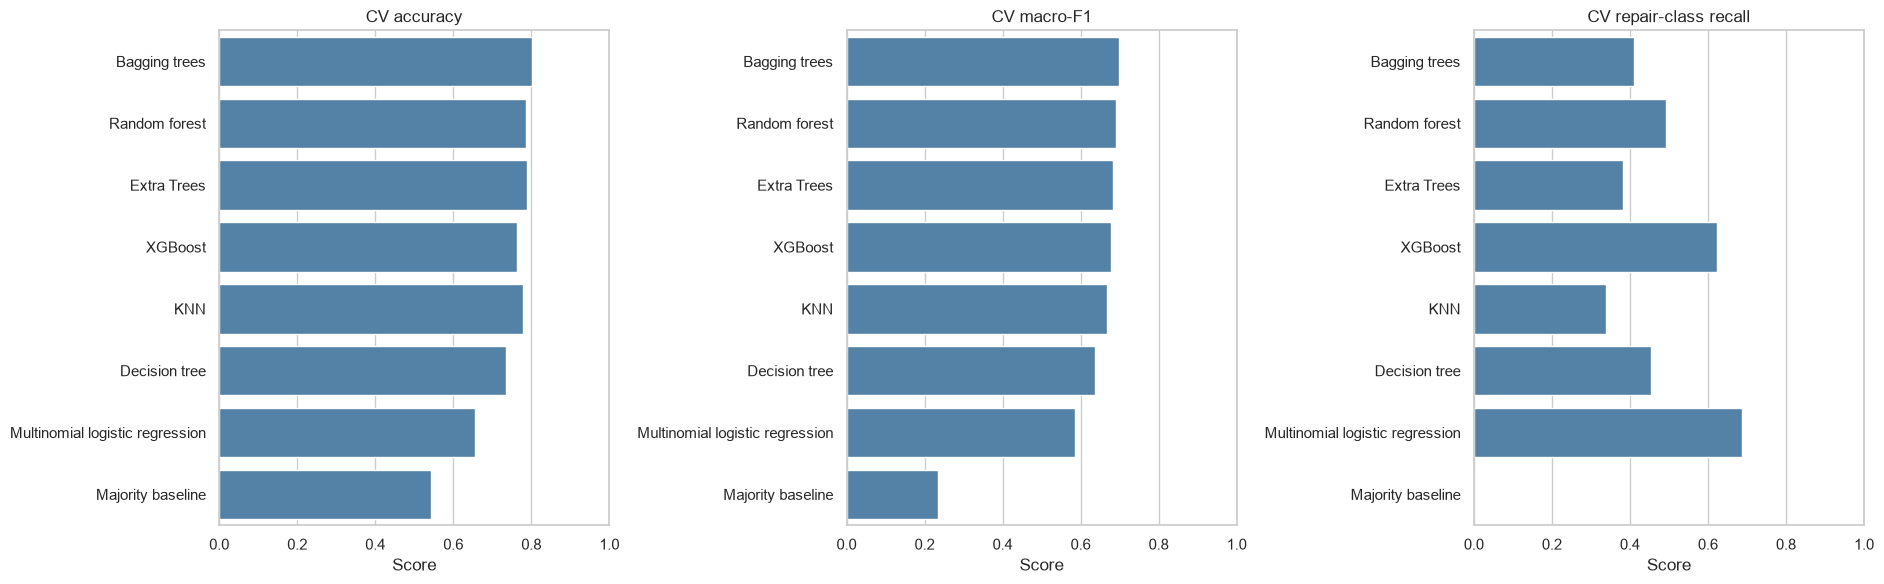

In [16]:
# Accuracy, macro-F1, and repair recall answer different questions.
# Fold standard deviations are variability measures, not confidence intervals.

fig, axes = plt.subplots(1, 3, figsize=(19, 6))

metrics = [
    ("cv_accuracy", "CV accuracy"),
    ("cv_macro_f1", "CV macro-F1"),
    ("cv_repair_recall", "CV repair-class recall"),
]

for ax, (metric, title) in zip(axes, metrics):
    sns.barplot(
        data=results,
        x=metric,
        y="model",
        order=results["model"].tolist(),
        color="steelblue",
        seed=SEED,
        ax=ax,
    )

    ax.set(title=title, xlabel="Score", ylabel="", xlim=(0, 1))

plt.tight_layout()
plt.show()


### Interpretation of the model comparison

**Bagging trees** ranks first on mean CV macro-F1 (**0.6971**), with accuracy **80.10%** and repair recall **41.11%**. Its macro-F1 standard deviation is **0.0083**; accuracy varies by **0.50 percentage points** across folds. The selected configuration uses 100 bootstrap trees, a sampling fraction of **0.7**, and a minimum base-tree leaf size of **2**, with balanced training weights.

Random forest is close behind at macro-F1 **0.6910**, with higher repair recall (**49.22%**) but lower accuracy (**78.66%**). The macro-F1 gap of **0.0061** is small relative to fold variability, so these scores alone do not establish a reliable superiority of bagging.

Logistic regression achieves the highest repair recall (**68.85%**) but macro-F1 of only **0.5854** and accuracy of **65.59%**. XGBoost reaches repair recall **62.22%**, macro-F1 **0.6785**, and accuracy **76.40%**. These results show why selecting by repair recall alone would answer a different question from selecting by macro-F1. KNN reaches macro-F1 **0.6667**, accuracy **77.93%**, and repair recall **33.85%**.

The majority baseline has macro-F1 **0.2346**, accuracy **54.31%**, and zero repair recall. Bagging therefore improves accuracy by **25.79 percentage points** and macro-F1 by approximately **0.463** over that reference. This comparison uses 47,520 development records and five folds; configuration selection may still make CV scores optimistic.


## 7. Holdout evaluation

The selected bagging model is evaluated on 11,880 reserved records alongside the majority baseline. It achieves accuracy **80.40%** and macro-F1 **0.6923**, compared with **54.31%** and **0.2346** for the baseline. The close CV and holdout macro-F1 scores suggest similar performance across this split, without establishing generalization to other regions or periods.

The rounded classification report shows repair precision of approximately **46%**, recall of **39%**, and F1 of **0.42**. Thus, most repair cases are still missed, and fewer than half of predictions specifically labeled as needing repair are correct. Functional recall is approximately **87%**; non-functional recall is **78%**.

The count confusion matrix shows error volumes; the row-normalized matrix shows how predictions are distributed within each actual class. Misclassifying an attention case as functional can leave it uninspected, while flagging a functional site consumes inspection capacity. The holdout was excluded from training and grid searches, but prior review of its results limits claims of evaluation independence.


,model,holdout_accuracy,holdout_macro_f1
0,Bagging trees,0.804040,0.692296
1,Majority baseline,0.543098,0.234635


                         precision    recall  f1-score   support

             functional       0.81      0.87      0.84      6452
functional needs repair       0.46      0.39      0.42       863
         non functional       0.85      0.78      0.81      4565

               accuracy                           0.80     11880
              macro avg       0.71      0.68      0.69     11880
           weighted avg       0.80      0.80      0.80     11880



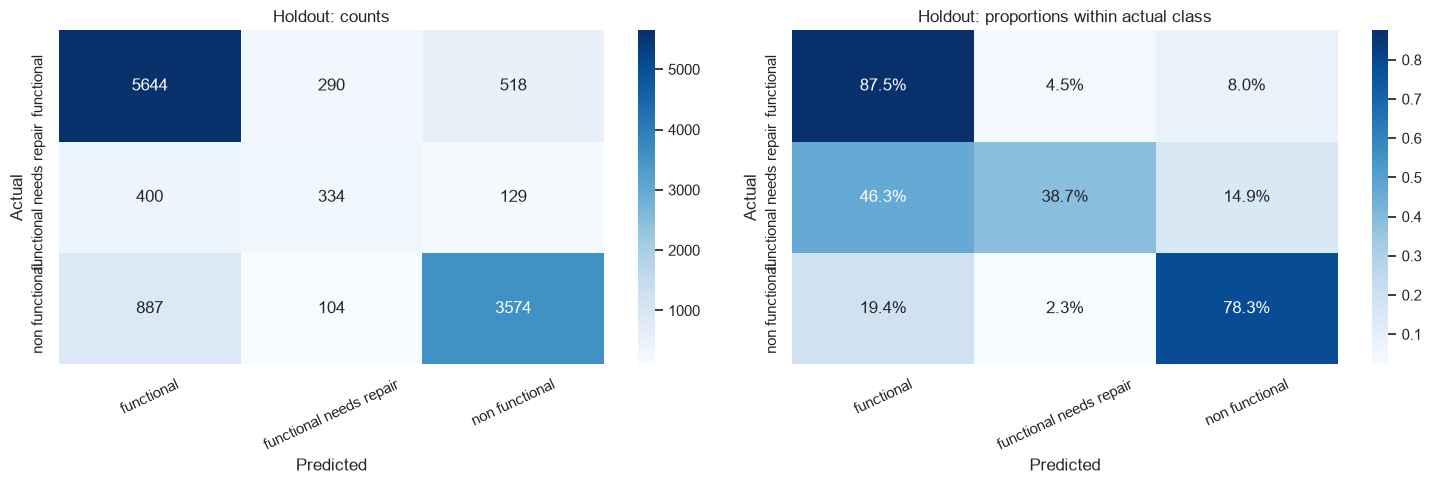

In [17]:
# Holdout results are reported only after model selection.


def predict_in_batches(model, frame, batch_size=500):
    predictions = []

    for start in range(0, len(frame), batch_size):
        batch = frame.iloc[start : start + batch_size]
        predictions.append(model.predict(batch))

    return np.concatenate(predictions).astype(int)


holdout_evaluated = False

if QUICK_RUN or not RUN_FINAL_EVALUATION:
    print("Holdout evaluation is not included in this run.")
else:
    if not X_fit.index.equals(X_dev_clean.index) or not y_fit.index.equals(y_dev.index):
        raise RuntimeError("Rerun model selection on the full development set.")

    holdout_pred = predict_in_batches(winner, X_holdout_clean)

    comparisons = [(winner_name, holdout_pred)]
    if winner_name != "Majority baseline":
        baseline = searches["Majority baseline"].best_estimator_
        baseline_pred = predict_in_batches(baseline, X_holdout_clean)
        comparisons.append(("Majority baseline", baseline_pred))

    final_rows = []

    for name, prediction in comparisons:
        final_rows.append(
            {
                "model": name,
                "holdout_accuracy": accuracy_score(y_holdout, prediction),
                "holdout_macro_f1": f1_score(y_holdout, prediction, average="macro"),
            }
        )

    final_scores = pd.DataFrame(final_rows)
    display(final_scores)
    final_scores.to_csv(OUTPUT_DIR / "holdout_scores.csv", index=False)

    print(
        classification_report(
            y_holdout,
            holdout_pred,
            labels=[0, 1, 2],
            target_names=CLASS_NAMES,
            zero_division=0,
        )
    )

    fig, axes = plt.subplots(1, 2, figsize=(15, 5))

    for ax, normalization, title, number_format in [
        (axes[0], None, "Holdout: counts", "d"),
        (axes[1], "true", "Holdout: proportions within actual class", ".1%"),
    ]:
        matrix = confusion_matrix(
            y_holdout, holdout_pred, labels=[0, 1, 2], normalize=normalization
        )

        sns.heatmap(
            matrix,
            annot=True,
            fmt=number_format,
            cmap="Blues",
            xticklabels=CLASS_NAMES,
            yticklabels=CLASS_NAMES,
            ax=ax,
        )

        ax.set(title=title, xlabel="Predicted", ylabel="Actual")
        ax.tick_params(axis="x", rotation=25)

    plt.tight_layout()
    plt.show()

    holdout_evaluated = True


## 8. Illustrative inspection policy

The policy flags waterpoints predicted as either needing repair or non-functional. For this scenario, both actual classes are combined as **attention cases**. Inspection yield is the share of flagged sites actually needing attention; coverage is the share of all attention cases flagged. These are broader measures than repair-class precision and recall.

The cost example assigns **20 arbitrary units per inspection** and **100 per missed attention case**. Targeted cost includes inspections of flagged sites plus penalties for missed attention cases. Inspecting every site incurs an inspection cost at every site and leaves no sites uninspected under this simplified assumption.

The comparison excludes travel, repair costs, inspection errors, capacity constraints, and future outcomes. It describes a hypothetical decision rule rather than measured financial savings. Uniform random inspection has expected yield equal to the holdout attention prevalence.


In [18]:
# Flag pumps predicted as needing repair or being non-functional.
# This policy does not change the original three-class model.
# The cost values below are hypothetical, not measured savings.

if not holdout_evaluated:
    print("Inspection-policy results require the final holdout predictions.")
else:
    actual_attention = y_holdout.to_numpy() != 0
    flagged = holdout_pred != 0

    true_positive = np.sum(flagged & actual_attention)
    false_positive = np.sum(flagged & ~actual_attention)
    false_negative = np.sum(~flagged & actual_attention)

    inspection_yield = true_positive / max(flagged.sum(), 1)
    coverage = true_positive / max(actual_attention.sum(), 1)

    display(
        pd.Series(
            {
                "pumps_flagged": int(flagged.sum()),
                "attention_cases_found": int(true_positive),
                "functional_pumps_flagged": int(false_positive),
                "attention_cases_missed": int(false_negative),
                "inspection_yield": inspection_yield,
                "coverage": coverage,
                "random_inspection_expected_yield": actual_attention.mean(),
            }
        )
    )

    # Illustrative cost assumptions, not observed financial outcomes.
    inspection_cost = 20
    missed_case_penalty = 100

    model_cost = flagged.sum() * inspection_cost + false_negative * missed_case_penalty
    inspect_all_cost = len(y_holdout) * inspection_cost

    print("Hypothetical model-policy cost:", model_cost)
    print("Hypothetical inspect-all cost:", inspect_all_cost)
    print("Hypothetical difference:", inspect_all_cost - model_cost)

    # Positive difference favors the model under these assumptions.
    # This scenario excludes repair costs, travel, and actual field outcomes.


pumps_flagged                       4949.000000
attention_cases_found               4141.000000
functional_pumps_flagged             808.000000
attention_cases_missed              1287.000000
inspection_yield                       0.836735
coverage                               0.762896
random_inspection_expected_yield       0.456902
dtype: float64

Hypothetical model-policy cost: 227680
Hypothetical inspect-all cost: 237600
Hypothetical difference: 9920


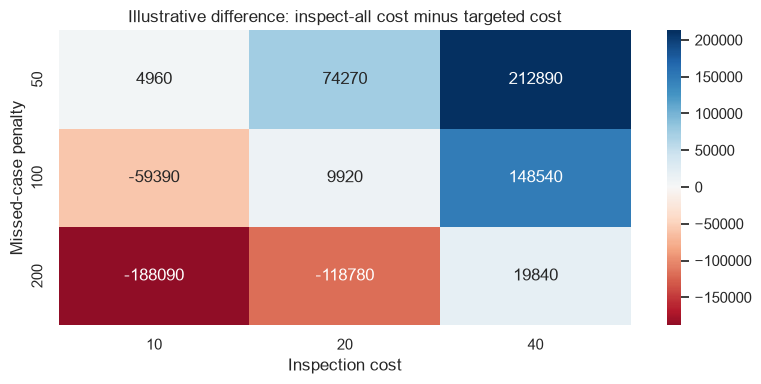

In [19]:
if holdout_evaluated:
    cost_sensitivity = pd.DataFrame(
        {
            cost: [
                (len(y_holdout) - flagged.sum()) * cost - false_negative * penalty
                for penalty in [50, 100, 200]
            ]
            for cost in [10, 20, 40]
        },
        index=pd.Index([50, 100, 200], name="Missed-case penalty"),
    )
    plt.figure(figsize=(8, 4))
    sns.heatmap(cost_sensitivity, annot=True, fmt=".0f", cmap="RdBu", center=0)
    plt.xlabel("Inspection cost")
    plt.title("Illustrative difference: inspect-all cost minus targeted cost")
    plt.tight_layout()
    plt.show()


### Interpretation of the inspection scenario

The policy flags **4,949 of 11,880 waterpoints (41.66%)**. Of those flagged, **4,141** actually need attention and **808** are functional. Inspection yield is **83.67%**, compared with an expected **45.69%** for uniform random inspection. Coverage is **76.29%**: the policy misses **1,287 of 5,428 attention cases**.

Under the illustrative 20/100 assumptions, targeted cost is **227,680 units**, compared with **237,600 units** for inspecting every site. The difference is **9,920 units** in favor of targeted inspection. This is conditional on the chosen costs and simplified policy assumptions.

The heatmap shows how that difference changes with inspection cost and missed-case penalty. Higher penalties can reverse the apparent advantage of targeting. Local cost estimates and prospective field evaluation are needed before using this calculation for resource allocation.


## 9. Refit and create the submission

After recording holdout results, the code clones the selected bagging configuration and fits it on all **59,400 labeled waterpoints**. Balanced training weights are recalculated during this fit. This refitted model generates competition predictions; the reported holdout scores belong to the earlier development-trained model.

Predictions are converted back to the exact competition labels and aligned to the submission template by `id`. Assertions check columns, row count, ID order, label completeness, and allowed label values. The saved `outputs/submission.csv` contains **14,850 predictions**. Without test labels or a competition score, these predictions provide no additional local performance estimate.

Predictions are processed in batches of **500 records** to limit prediction-time memory use. Grid searches run sequentially with one search worker; supported estimators use two workers internally. These execution choices control resource use and do not change the intended selection metric or weighting rule.


In [20]:
# After recording holdout performance, use all 59,400 labeled pumps.
# Convert numeric predictions back to the exact required class names.

if not holdout_evaluated:
    print("Competition predictions are not generated in this run.")
else:
    final_model = clone(winner)
    final_model.fit(engineer_features(X), y)

    test_predictions = predict_in_batches(final_model, X_test_clean)

    predictions_by_id = pd.Series(test_predictions, index=test_values["id"]).map(
        number_to_label
    )

    # Map by ID rather than assuming the template has the same row order.
    submission = submission_format[["id"]].copy()
    submission["status_group"] = submission["id"].map(predictions_by_id)

    assert submission.columns.tolist() == ["id", "status_group"]
    assert len(submission) == len(test_values)
    assert submission["id"].equals(submission_format["id"])
    assert submission["status_group"].notna().all()
    assert set(submission["status_group"]).issubset(CLASS_NAMES)

    submission_path = OUTPUT_DIR / "submission.csv"
    submission.to_csv(submission_path, index=False)

    display(submission.head())
    print("Saved:", submission_path)


/Users/mayed/Documents/AI7101/Project/pump-it-up-water-pumps/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


,id,status_group
0,50785,functional
1,51630,functional
2,17168,functional
3,45559,non functional
4,49871,functional


Saved: /Users/mayed/Documents/AI7101/Project/pump-it-up-water-pumps/outputs/submission.csv


## 10. Limitations and practical use

- **Repair detection:** holdout repair recall is approximately 39%, so most repair cases remain unidentified as that specific class. Broader attention-case coverage does not eliminate this limitation.
- **Evaluation independence:** the holdout was excluded from fitting and grid searches, but its results have been inspected during project development. A fresh evaluation is needed before making strong final-performance claims.
- **Geographic and temporal shift:** random splits can place nearby or related sites in both sets. Grouped regional and temporal validation would better test transfer to new settings.
- **Predictor availability:** observed water quantity and other site attributes may require a visit. Deployment requires checking which inputs are available before deciding where to inspect.
- **Feature and search scope:** dropping detailed location fields and grouping rare categories can remove useful signal. Compact grids do not establish the best achievable performance.
- **Weighting effects:** inverse-frequency weights emphasize rare classes but do not guarantee useful recall, calibrated probabilities, or an acceptable false-alarm rate.
- **Operational evidence:** these historical labels describe recorded condition. The analysis does not measure future failure, drinking-water safety, realized savings, or the causal effect of maintenance.


## 11. Overall conclusion

**Bagging trees** is the selected model under macro-F1-based cross-validation with fixed balanced training weights. It achieves holdout accuracy **80.40%** and macro-F1 **0.6923**, substantially above the majority baseline. Repair detection remains a weakness: the rounded holdout report gives repair recall of approximately **39%** and precision of **46%**.

When repair and non-functional predictions are combined into an inspection flag, the policy reaches **76.29% attention-case coverage** and **83.67% inspection yield**, while inspecting **41.66%** of holdout sites. It still misses **1,287 attention cases**. The illustrative cost advantage of **9,920 units** depends on assumptions and is not evidence of realized savings.

The results support further investigation of prediction-assisted inspection prioritization. Next steps are evaluation across regions and collection periods, closer analysis of repair-class errors, verification of pre-inspection feature availability, and a field pilot with locally justified costs and inspection capacity. Prior holdout review also makes a fresh evaluation important before drawing final deployment conclusions.


## References

1. [DrivenData: Pump It Up data and target documentation](https://www.drivendata.org/competitions/7/pump-it-up-data-mining-the-water-table/page/25/).
2. [Scikit-learn: GridSearchCV and model refitting](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GridSearchCV.html).
3. [Scikit-learn: cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html).
4. [Scikit-learn: balanced sample weights](https://scikit-learn.org/stable/modules/generated/sklearn.utils.class_weight.compute_sample_weight.html).
5. [Scikit-learn: classification metrics](https://scikit-learn.org/stable/modules/model_evaluation.html#classification-metrics).
6. [XGBoost: Python API and sample-weight support](https://xgboost.readthedocs.io/en/stable/python/python_api.html).
